# 02 — Exploratory Data Analysis

Generate descriptive tables, age-specific mortality curves, and survival curves. Save the four report-ready outputs.

## Project setup

Run this notebook from the repository root or from the `notebooks/` directory. All paths are resolved to the repository root. This project uses the `src/` helper modules already present in your repository; the original report did not include their source code.

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
project_root = cwd if (cwd / "src").is_dir() else cwd.parent
if not (project_root / "src").is_dir():
    raise FileNotFoundError(
        "Project root not found. Open the repository in VS Code and run the notebook from the repository root or notebooks/."
    )
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
report_results_dir = project_root / "results"
report_results_dir.mkdir(parents=True, exist_ok=True)
figures_dir = project_root / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)


In [2]:
clean_path = project_root / "data" / "processed" / "ssa_mortality_clean.csv"
if not clean_path.is_file():
    raise FileNotFoundError(
        "Run notebook 01 first to generate data/processed/ssa_mortality_clean.csv"
    )
mortality = pd.read_csv(clean_path)
print("Loaded", len(mortality), "mortality records")


Loaded 240 mortality records


## Descriptive statistics and selected ages

In [3]:
# Descriptive analysis of the mortality dataset

summary = mortality.groupby("sex").agg(
    observations=("age", "count"),
    minimum_age=("age", "min"),
    maximum_age=("age", "max"),
    mean_qx=("qx", "mean"),
    minimum_qx=("qx", "min"),
    maximum_qx=("qx", "max")
)

display(summary.round(6))

# Examine mortality assumptions at selected ages
selected_ages = [0, 20, 40, 50, 60, 80, 100]

selected_mortality = mortality[
    mortality["age"].isin(selected_ages)
]

display(
    selected_mortality.pivot(
        index="age",
        columns="sex",
        values="qx"
    ).round(6)
)

,observations,minimum_age,maximum_age,mean_qx,minimum_qx,maximum_qx
sex,,,,,,
Female,120,0,119,0.126751,0.000098,0.926604
Male,120,0,119,0.135420,0.000120,0.926604


sex,Female,Male
age,,
0,0.005125,0.006015
20,0.000441,0.001235
40,0.001643,0.003115
50,0.003030,0.005126
60,0.006923,0.011337
80,0.041183,0.055633
100,0.329680,0.366568


## Age-specific mortality probabilities

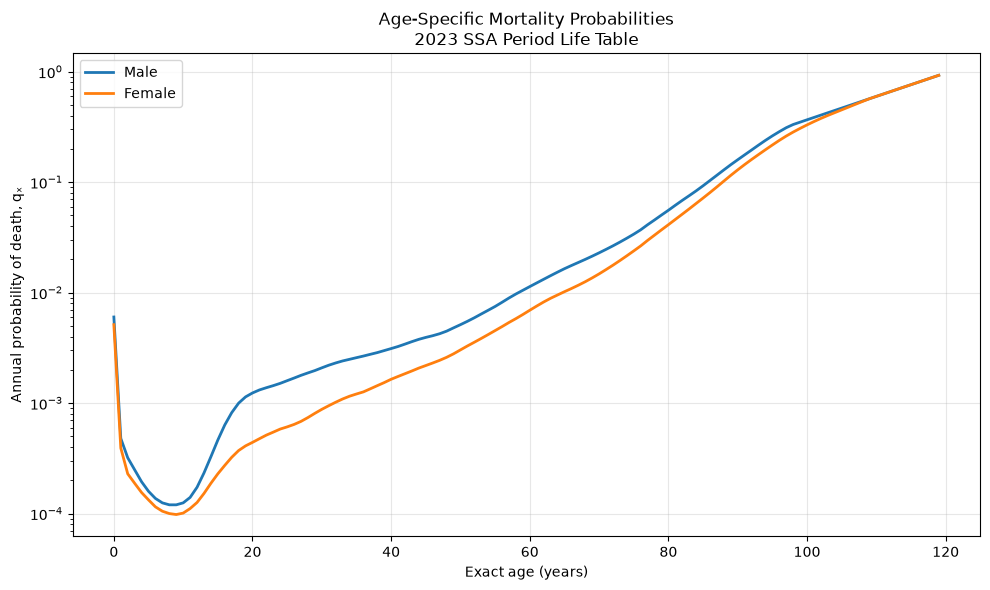

In [4]:
import matplotlib.pyplot as plt
from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 6))

for sex in ["Male", "Female"]:
    subset = mortality[
        mortality["sex"] == sex
    ].sort_values("age")

    ax.plot(
        subset["age"],
        subset["qx"],
        linewidth=2,
        label=sex
    )

ax.set_yscale("log")
ax.set_xlabel("Exact age (years)")
ax.set_ylabel("Annual probability of death, qₓ")
ax.set_title(
    "Age-Specific Mortality Probabilities\n"
    "2023 SSA Period Life Table"
)

ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()

fig.savefig(
    figures_dir / "mortality_by_age.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Cumulative 20-year survival from age 40

Male: 20-year survival probability = 0.892496
Male: 20-year death probability = 0.107504
Female: 20-year survival probability = 0.935602
Female: 20-year death probability = 0.064398


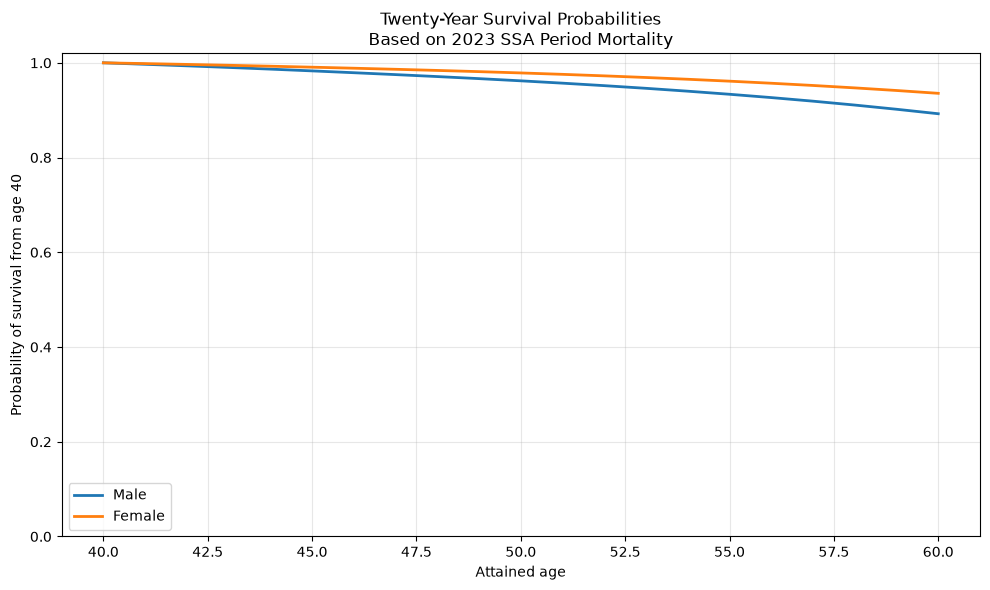

In [5]:
import numpy as np

entry_age = 40
term = 20

fig, ax = plt.subplots(figsize=(10, 6))

for sex in ["Male", "Female"]:

    subset = (
        mortality[mortality["sex"] == sex]
        .set_index("age")
        .sort_index()
    )

    ages = np.arange(entry_age, entry_age + term)

    qx = subset.loc[ages, "qx"].to_numpy()

    survival = np.concatenate([
        [1.0],
        np.cumprod(1 - qx)
    ])

    attained_ages = np.arange(
        entry_age,
        entry_age + term + 1
    )

    ax.plot(
        attained_ages,
        survival,
        linewidth=2,
        label=sex
    )

    print(
        f"{sex}: 20-year survival probability = "
        f"{survival[-1]:.6f}"
    )

    print(
        f"{sex}: 20-year death probability = "
        f"{1 - survival[-1]:.6f}"
    )

ax.set_xlabel("Attained age")
ax.set_ylabel("Probability of survival from age 40")
ax.set_title(
    "Twenty-Year Survival Probabilities\n"
    "Based on 2023 SSA Period Mortality"
)

ax.set_ylim(0, 1.02)
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    figures_dir / "survival_probabilities.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Export tables for the narrative report

In [ ]:
def write_report_table(frame, filename, *, include_index=False, floatfmt=None):
    """Write an output table that the code-free Quarto report can include."""
    kwargs = {"index": include_index}
    if floatfmt is not None:
        kwargs["floatfmt"] = floatfmt
    (report_results_dir / filename).write_text(
        frame.to_markdown(**kwargs) + "\n", encoding="utf-8"
    )

summary_report = summary.reset_index().rename(columns={
    "sex":"Sex", "observations":"Observations", "minimum_age":"Minimum age",
    "maximum_age":"Maximum age", "mean_qx":"Mean qₓ",
    "minimum_qx":"Minimum qₓ", "maximum_qx":"Maximum qₓ"
})
write_report_table(summary_report, "03_descriptive_summary.qmd", floatfmt=".6f")
selected_report = selected_mortality.pivot(index="age", columns="sex", values="qx").reset_index()
selected_report.columns.name = None
selected_report = selected_report.rename(columns={"age":"Age","Female":"Female qₓ","Male":"Male qₓ"})
write_report_table(
    selected_report,
    "04_selected_age_mortality.qmd",
    floatfmt=(".0f", ".6f", ".6f")
)
survival_summary = []
for sex in ["Male", "Female"]:
    q = mortality.loc[(mortality["sex"] == sex) & mortality["age"].between(40, 59)]
    q = q.sort_values("age")["qx"].to_numpy()
    p20 = float(np.prod(1 - q))
    survival_summary.append({
        "Mortality schedule": sex,
        "20-year survival": f"{p20:.4%}",
        "20-year death": f"{1-p20:.4%}",
    })
write_report_table(pd.DataFrame(survival_summary), "05_survival_summary.qmd")
print("Updated descriptive and survival tables. Figures were saved by the plotting cells.")


Updated descriptive and survival tables. Figures were saved by the plotting cells.
